# Step 2e: explaining the multimodal fusion model

**Model (1):** the fusion network. For every account it reads three **blocks** of input:

| Block | Input |
|---|---|
| `tab` | the 12 standardised profile stats |
| `text` | the account's text embedding (mean `[CLS]` vector of its posts from the frozen step-1 transformer) |
| `graph` | the interaction graph (two GCN layers over the neighbours' fused vectors) |

**Unit of explanation: the block.** This is a coarser question than in the other notebooks: not "which word" or "which edge", but "which kind of evidence did the model rely on for this account?".

**Two explanation methods**

1. **Block Shapley values.** The model is evaluated on every combination of present / absent blocks (2^3 = 8 combinations), and each block receives its exact Shapley value: its average marginal contribution to the logit over all orders of adding the blocks. With three players this is exact, with no sampling.
2. **Drop-one-modality ablation.** For each block, how much does the logit fall when that block alone is removed?

"Absent" means: `tab` and `text` are replaced by their training average (a vector of zeros after standardisation) **for every account**, and `graph` is replaced by an empty graph (each account only sees itself). The block is removed from the model's input as a whole, not just for the explained account.

**What is and is not scored.** The block weights have no answer key (the data were not generated with block weights), so **there is no correctness score**. Instead:
* we compare the model with the single-modality models it is built from (section 3);
* we check the block explanations against the answer key *descriptively* (section 6): does the text block follow the number of marker words, the graph block follow ring membership and degree, the tab block follow the planted logit?
* faithfulness, agreement and stability are scored as in the other notebooks.

Everything is computed for **all 1,000 test accounts** (it takes seconds: 8 forward passes of the network). `QUICK` is not needed.

## 0. Setup

In [1]:
import sys
import time
import warnings
from pathlib import Path

REPO_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(REPO_ROOT))  # so `import xai_eval` works from notebooks/

import xai_eval  # noqa: F401  (imports xgboost / lightgbm before torch: macOS OpenMP workaround)
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import display

from xai_eval import data as xd
from xai_eval import io as xio
from xai_eval import loaders as L
from xai_eval import metrics as xm

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)
pd.set_option("display.width", 160)
torch.set_num_threads(4)

from itertools import combinations
from math import factorial

from sklearn.metrics import roc_auc_score
from scipy.stats import spearmanr

In [2]:
SEED = 0
NOISE_FRAC = 0.05  # stability: noise std as a share of each (standardised) input's std
KS = [1, 2]  # blocks deleted in the faithfulness test
N_RANDOM = 5
BLOCKS = ["tab", "text", "graph"]
FAMILY = "multimodal"
np.random.seed(SEED)
torch.manual_seed(SEED)

## 1. Data and the fusion model

In [3]:
D = xd.load_data(REPO_ROOT)
N = D.n
TEST = np.flatnonzero(D.is_te)
KIND_T = D.kind[TEST]
print(
    "test accounts by kind:",
    {k: int((KIND_T == k).sum()) for k in ("human", "bot", "troll")},
)

test accounts by kind: {'human': 686, 'bot': 188, 'troll': 137}


## 2. Reload the model and check it

The text block needs the step-1 transformer (to turn posts into the account's text embedding) and the scaler fitted in step 1.

In [4]:
transformer = L.load_model("transformer", D)
fusion = L.load_model("multimodal_fusion", D)
X_TAB, X_TXT = L.fusion_inputs(
    D, transformer
)  # (5000, 12), (5000, 64): the model's own inputs
EMPTY = torch.empty((2, 0), dtype=torch.long)  # a graph with no edges


def fusion_logits(x_tab, x_txt, edge_index):
    fusion.eval()
    with torch.no_grad():
        return fusion(x_tab, x_txt, edge_index).numpy()


CHECKS = [
    L.verify_reload(
        "multimodal_fusion", D, L.sigmoid(fusion_logits(X_TAB, X_TXT, D.EDGE_INDEX))
    )
]
assert all(
    c["status"] == "OK" for c in CHECKS
), "The reloaded model does not match its step-1 predictions"

  reload check multimodal_fusion    max|diff|=1.11e-16  spearman=1.0000  -> OK


## 3. The eight coalitions, and how the blocks perform alone

`v(S)` is the model's logit for every account when only the blocks in `S` are present. The table shows the test AUC of `v(S)`: how well each combination of evidence separates inauthentic from authentic accounts. Single blocks are compared with the single-modality models fitted in step 1.

In [5]:
def coalition_logits(present, x_tab=X_TAB, x_txt=X_TXT, ei=D.EDGE_INDEX):
    """Logit of every account when only the blocks in `present` are given to the model."""
    t = (
        x_tab if "tab" in present else torch.zeros_like(x_tab)
    )  # zeros = the training mean (inputs are standardised)
    x = x_txt if "text" in present else torch.zeros_like(x_txt)
    g = ei if "graph" in present else EMPTY
    return fusion_logits(t, x, g)


SUBSETS = [
    frozenset(c) for r in range(len(BLOCKS) + 1) for c in combinations(BLOCKS, r)
]
V = {S: coalition_logits(S) for S in SUBSETS}  # 8 forward passes
SD = float(np.std(V[frozenset(BLOCKS)][TEST]))  # scale for the faithfulness test

rows = [
    dict(
        present="+".join(b for b in BLOCKS if b in S) or "(nothing)",
        test_auc=roc_auc_score(D.y[TEST], V[S][TEST]),
    )
    for S in SUBSETS
]
COAL = pd.DataFrame(rows).set_index("present")
display(COAL.round(3))

m1 = pd.read_csv(D.root / "outputs" / "step1_fit" / "metrics.csv").set_index("model")
ref = m1.loc[
    ["transformer", "rf", "svm_rbf", "gcn", "multimodal_fusion"], ["test_roc_auc"]
].rename(columns={"test_roc_auc": "step-1 test AUC"})
print("Single-modality models from step 1 (for comparison):")
display(ref.round(3))

,test_auc
present,
(nothing),0.500
tab,0.766
text,0.873
graph,0.422
tab+text,0.900
tab+graph,0.767
text+graph,0.932
tab+text+graph,0.948


Single-modality models from step 1 (for comparison):


,step-1 test AUC
model,
transformer,0.873
rf,0.829
svm_rbf,0.822
gcn,0.965
multimodal_fusion,0.948


A caution before reading it: an "absent" block is an input the model was never trained on (it always saw all three), so coalitions with missing blocks are partly off-distribution. A single block with an AUC below 0.5 does not mean the block is anti-informative; it means that, without the other blocks, the model's logit is not a sensible score. Shapley values and ablations inherit this limit.

Reading it: if `text` alone is about as good as the whole model, the fusion network is essentially a text classifier with some extra evidence. If `graph` alone is much weaker than the GCN in step 1, the fusion model has not learned to use structure as well as the GCN could. This is the context in which the block explanations below should be read.

## 4. The two explanation methods

In [6]:
def shapley(v):
    """Exact Shapley values of the three blocks from a dict {frozenset(present): value array}. Returns (n_accounts, 3)."""
    n = len(BLOCKS)
    phi = np.zeros((len(next(iter(v.values()))), n))
    for i, b in enumerate(BLOCKS):
        others = [x for x in BLOCKS if x != b]
        for r in range(len(others) + 1):
            for S in combinations(others, r):
                S = frozenset(S)
                w = factorial(len(S)) * factorial(n - len(S) - 1) / factorial(n)
                phi[:, i] += w * (v[S | {b}] - v[S])
    return phi


def ablation(v):
    """Drop-one-modality effect: logit with everything minus logit without block b. (n_accounts, 3)."""
    full = v[frozenset(BLOCKS)]
    return np.stack([full - v[frozenset(BLOCKS) - {b}] for b in BLOCKS], axis=1)


PHI = shapley(V)
ABL = ablation(V)
# Shapley values add up to (all blocks) - (no blocks): the efficiency property, checked here
assert np.allclose(PHI.sum(1), V[frozenset(BLOCKS)] - V[frozenset()], atol=1e-5)
print("Shapley efficiency check passed")

Shapley efficiency check passed


mean_share               mean_value              
block                        graph    tab   text      graph    tab   text
method            kind                                                   
Block Shapley     bot        0.282  0.163  0.556      0.840 -0.379  3.498
                  human      0.263  0.227  0.510      2.233 -1.854 -4.638
                  troll      0.343  0.141  0.516      1.843 -0.148  4.287
Drop-one ablation bot        0.403  0.129  0.469      1.619 -0.565  4.289
                  human      0.469  0.218  0.313      4.404 -1.987 -2.482
                  troll      0.401  0.089  0.509      3.660 -0.277  6.147

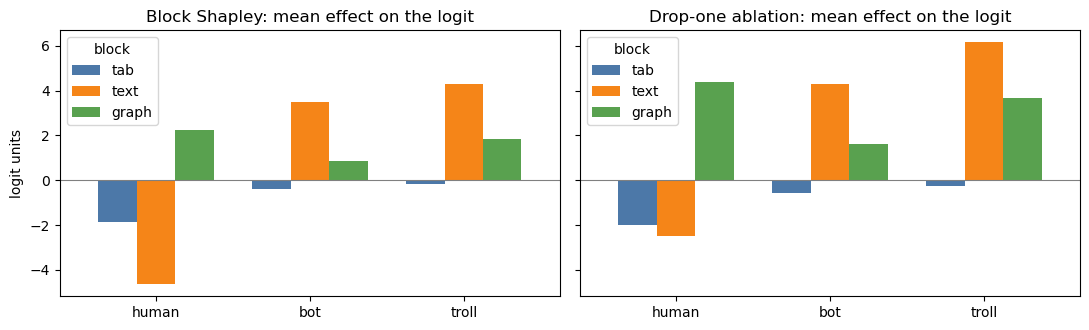

In [7]:
# Average block weight by account kind: signed (pushes towards 'inauthentic' if positive) and share of total |value|
rows = []
for k in ("human", "bot", "troll"):
    sel = KIND_T == k
    for name, M in [("Block Shapley", PHI), ("Drop-one ablation", ABL)]:
        a = M[TEST][sel]
        share = np.abs(a) / np.abs(a).sum(1, keepdims=True)
        for i, b in enumerate(BLOCKS):
            rows.append(
                dict(
                    kind=k,
                    method=name,
                    block=b,
                    mean_value=a[:, i].mean(),
                    mean_share=share[:, i].mean(),
                )
            )
BYKIND = pd.DataFrame(rows)
display(
    BYKIND.pivot_table(
        index=["method", "kind"], columns="block", values=["mean_value", "mean_share"]
    ).round(3)
)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.4), sharey=True)
for ax, name in zip(axes, ["Block Shapley", "Drop-one ablation"]):
    d = (
        BYKIND[BYKIND.method == name]
        .pivot(index="kind", columns="block", values="mean_value")
        .loc[["human", "bot", "troll"], BLOCKS]
    )
    d.plot.bar(ax=ax, rot=0, color=["#4C78A8", "#F58518", "#59A14F"], width=0.75)
    ax.axhline(0, color="gray", lw=0.8)
    ax.set_title(f"{name}: mean effect on the logit")
    ax.set_xlabel("")
axes[0].set_ylabel("logit units")
plt.tight_layout()
plt.show()

## 5. Evaluation: faithfulness, agreement, stability

* **Faithfulness:** delete the top-ranked block(s) for each account (by |value|) versus a random block, and measure the change in the logit (in units of the logit's standard deviation on the test set). Careful: for the *ablation* method this test is partly circular (the top-ranked block is, by definition, the one whose removal changes the logit most among single blocks), so it is a sanity check rather than evidence. It is informative for Shapley values.
* **Agreement:** per account, the rank correlation between the two methods' |values| over the three blocks, and how often both rank the same block first.
* **Stability:** add small noise (5% of each input's std) to the profile stats and text embeddings of every account, recompute the explanations, and compare the block shares. Reported as `1 - 0.5 * L1 distance` between the share vectors (1 = identical).

In [8]:
SC = xm.Scorecard("multimodal")
INST_ROWS = []
METHODS = {"Block Shapley": PHI, "Drop-one ablation": ABL}
node_pos = {int(v): i for i, v in enumerate(TEST)}

# ---- faithfulness
subset_logit = lambda rows: np.array(
    [V[frozenset(BLOCKS) - set(rem)][TEST[i]] for i, rem in rows]
)  # noqa: E731
remove = lambda x, idx: (x[0], tuple(BLOCKS[j] for j in idx))  # noqa: E731
for m, M in METHODS.items():
    dele = xm.deletion_gain(
        subset_logit,
        [(i, ()) for i in range(len(TEST))],
        M[TEST],
        remove,
        KS,
        SD,
        n_random=N_RANDOM,
        seed=SEED,
    )
    dele.assign(model="multimodal_fusion", method=m).to_csv(
        xio.out_dir(D, FAMILY) / f"deletion_{m.replace(' ', '_')}.csv", index=False
    )
    faith = xm.mean_gain_per_instance(dele)
    SC.add("multimodal_fusion", m, "faithfulness", faith)
    for kind in ("human", "bot", "troll"):
        SC.add("multimodal_fusion", m, f"faithfulness_{kind}", faith[KIND_T == kind])
    for i, f in enumerate(faith):
        INST_ROWS.append(
            dict(method=m, account_id=int(TEST[i]), kind=KIND_T[i], faithfulness=f)
        )

# ---- agreement
a, b = np.abs(PHI[TEST]), np.abs(ABL[TEST])
SC.add(
    "multimodal_fusion",
    "Shapley vs ablation",
    "agreement_spearman",
    [xm.rank_corr(x, y) for x, y in zip(a, b)],
)
SC.add(
    "multimodal_fusion",
    "Shapley vs ablation",
    "agreement_top1",
    (a.argmax(1) == b.argmax(1)).astype(float),
)

# ---- stability: noise on the inputs of every account
g = torch.Generator().manual_seed(SEED + 1)
Xn_tab = X_TAB + NOISE_FRAC * torch.randn(X_TAB.shape, generator=g)
Xn_txt = X_TXT + NOISE_FRAC * torch.randn(X_TXT.shape, generator=g)
Vn = {S: coalition_logits(S, Xn_tab, Xn_txt) for S in SUBSETS}
shares = lambda M: np.abs(M[TEST]) / np.abs(M[TEST]).sum(1, keepdims=True)  # noqa: E731
for m, fn in [("Block Shapley", shapley), ("Drop-one ablation", ablation)]:
    s0, s1 = shares(METHODS[m]), shares(fn(Vn))
    SC.add("multimodal_fusion", m, "stability_noise", 1 - 0.5 * np.abs(s0 - s1).sum(1))
    SC.add(
        "multimodal_fusion",
        m,
        "repeatability_seed",
        1.0,
        "deterministic: exact computation",
    )
    SC.add(
        "multimodal_fusion",
        m,
        "seconds_per_explanation",
        0.0,
        "8 forward passes for all accounts together",
    )
display(SC.table().round(3))

criterion                              agreement_spearman  agreement_top1  faithfulness  faithfulness_bot  faithfulness_human  faithfulness_troll  \
model             method                                                                                                                            
multimodal_fusion Block Shapley                       NaN             NaN         0.171             0.272               0.095               0.410   
                  Drop-one ablation                   NaN             NaN         0.224             0.347               0.145               0.451   
                  Shapley vs ablation               0.458           0.551           NaN               NaN                 NaN                 NaN   

criterion                              repeatability_seed  seconds_per_explanation  stability_noise  
model             method                                                                             
multimodal_fusion Block Shapley                       1.0                      0.0            0.988  
                  Drop-one ablation                   1.0                      0.0            0.990  
                  Shapley vs ablation                 NaN                      NaN              NaN

In [9]:
# How often is each block the most important one, by kind (Shapley)?
top = pd.DataFrame(
    {"kind": KIND_T, "top_block": np.array(BLOCKS)[np.abs(PHI[TEST]).argmax(1)]}
)
display(pd.crosstab(top.kind, top.top_block, normalize="index").round(3)[BLOCKS])

top_block,tab,text,graph
kind,,,
bot,0.043,0.691,0.266
human,0.133,0.789,0.079
troll,0.029,0.584,0.387


## 6. Do the block explanations match the answer key? (descriptive, not scored)

The data were not generated with block weights, but each block has a known signal, so we can ask whether the block values *follow* it:

* the **text** value should rise with the number of planted marker words in the account's posts (an inauthentic account that happens to have none should get little text credit);
* the **graph** value should be higher for ring members (trolls) than for other accounts, and we also check how much it simply follows degree, the known confound;
* the **tab** value should follow the planted logit (`true_logit`), the Bayes-optimal profile-stats score.

These are rank correlations over the test accounts (or AUCs), with answer-key columns used only here.

In [10]:
n_markers = np.array(
    [sum(t in D.marker_set for t in D.account_tokens[i]) for i in range(N)]
)
n_spur = np.array(
    [sum(t == D.spurious_token for t in D.account_tokens[i]) for i in range(N)]
)
deg = np.bincount(np.r_[D.src, D.dst], minlength=N)
true_logit = D.truth["true_logit"].to_numpy()
is_troll = D.kind == "troll"

t = TEST
rho = lambda a, b: float(spearmanr(a, b)[0])  # noqa: E731
rows = []
for m, M in METHODS.items():
    bad = D.y[t] == 1
    rows.append(
        dict(
            method=m,
            text_vs_marker_count=rho(M[t, 1], n_markers[t]),
            text_vs_decoy_count=rho(M[t, 1], n_spur[t]),
            graph_auc_for_troll=roc_auc_score(is_troll[t], M[t, 2]),
            graph_vs_degree=rho(M[t, 2], deg[t]),
            tab_vs_planted_logit=rho(M[t, 0], true_logit[t]),
        )
    )
CHECK_KEY = pd.DataFrame(rows).set_index("method")
display(CHECK_KEY.round(3))

,text_vs_marker_count,text_vs_decoy_count,graph_auc_for_troll,graph_vs_degree,tab_vs_planted_logit
method,,,,,
Block Shapley,0.765,0.535,0.506,0.004,0.764
Drop-one ablation,0.751,0.492,0.507,0.006,0.773


How to read it: a high `graph_vs_degree` next to a modest `graph_auc_for_troll` would mean the graph block mostly reflects how many neighbours an account has, not the ring structure. A positive `text_vs_decoy_count` means the text block is credited for the decoy hashtag (the model learned the shortcut).

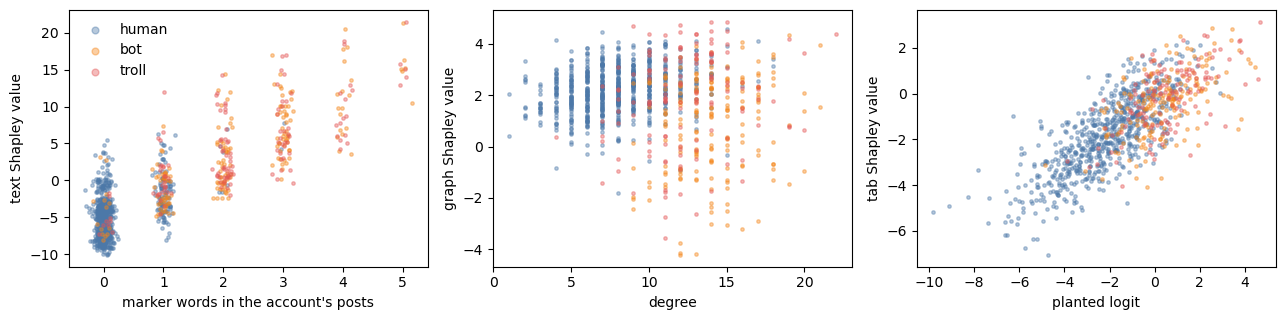

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.3))
colors = {"human": "#4C78A8", "bot": "#F58518", "troll": "#E45756"}
for ax, (i, b, xv, xl) in zip(
    axes,
    [
        (1, "text", n_markers, "marker words in the account's posts"),
        (2, "graph", deg, "degree"),
        (0, "tab", true_logit, "planted logit"),
    ],
):
    for k, c in colors.items():
        s = t[KIND_T == k]
        ax.scatter(
            xv[s] + np.random.default_rng(0).normal(0, 0.08 if i == 1 else 0, len(s)),
            PHI[s, i],
            s=6,
            alpha=0.4,
            color=c,
            label=k,
        )
    ax.set_xlabel(xl)
    ax.set_ylabel(f"{b} Shapley value")
axes[0].legend(frameon=False, markerscale=2)
plt.tight_layout()
plt.show()

## 7. Save

In [12]:
xio.save_scorecard(
    D,
    FAMILY,
    SC,
    reload_checks=CHECKS,
    meta=dict(seed=SEED, noise_frac=NOISE_FRAC, ks=KS, blocks=BLOCKS),
)
xio.save_table(D, FAMILY, "coalition_auc", COAL.reset_index())
xio.save_table(D, FAMILY, "block_values_by_kind", BYKIND)
xio.save_table(D, FAMILY, "block_vs_answer_key", CHECK_KEY.reset_index())
vals = pd.DataFrame(
    {
        "account_id": TEST,
        "kind": KIND_T,
        **{f"shapley_{b}": PHI[TEST, i] for i, b in enumerate(BLOCKS)},
        **{f"ablation_{b}": ABL[TEST, i] for i, b in enumerate(BLOCKS)},
    }
)
xio.save_table(D, FAMILY, "block_values", vals)
pd.DataFrame(INST_ROWS).to_csv(
    xio.out_dir(D, FAMILY) / "per_instance_scores.csv", index=False
)

saved /Users/ananyajogalekar/Library/CloudStorage/GoogleDrive-ananyajogalekar5@gmail.com/My Drive/Duke University/00-Coursework/AIPI590-XAI/Final_Project/github_repo/Explaining_Anonymity/outputs/step2_explain/multimodal/scorecard.csv


## 8. What to take from this notebook

1. Which block does the fusion model rely on for each kind of account? Does it match where the planted signal is (graph for trolls, text for both bots and trolls)?
2. Is the fusion model better explained as "mostly one modality" (section 3)? If so, the block explanation is a short story.
3. Do Shapley values and the ablation agree on the top block? Where they disagree, the model's blocks interact (the effect of removing one depends on what else is present).
4. Does the graph block reflect ring structure or degree, and does the text block reflect the decoy hashtag?

The fusion model is compared only with the single-modality models it is built from (section 3), not ranked against other groups.